In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["figure.dpi"] = 110

pat = re.compile(
    r"N=(\d+)\s+threads=(\d+)\s+inside=(\d+)"
    r"\s+pi=([\d.]+)\s+error=([\d.eE+-]+)\s+time=([\d.]+)"
)

rows = []
with open("result.txt", encoding="utf-8") as f:
    for line in f:
        m = pat.search(line)
        if m:
            rows.append(dict(
                N       = int(m.group(1)),
                threads = int(m.group(2)),
                inside  = int(m.group(3)),
                pi      = float(m.group(4)),
                error   = float(m.group(5)),
                time    = float(m.group(6)),
            ))

df = pd.DataFrame(rows).sort_values(["N", "threads"]).reset_index(drop=True)

# Ускорение и эффективность считаем относительно потока p=1 при том же N
df["speedup"] = df.groupby("N")["time"].transform(lambda s: s.iloc[0] / s)
df["efficiency"] = df["speedup"] / df["threads"]

Ns          = sorted(df["N"].unique())
threads_lst = sorted(df["threads"].unique())

print(f"Строк: {len(df)},  N = {Ns},  threads = {threads_lst}")

Строк: 16,  N = [np.int64(1000000), np.int64(10000000), np.int64(100000000), np.int64(1000000000)],  threads = [np.int64(1), np.int64(2), np.int64(4), np.int64(8)]


In [2]:
df

,N,threads,inside,pi,error,time,speedup,efficiency
0,1000000,1,785350,3.141400,0.000193,0.003,1.000000,1.000000
1,1000000,2,784944,3.139776,0.001817,0.002,1.500000,0.750000
2,1000000,4,785702,3.142808,0.001215,0.001,3.000000,0.750000
3,1000000,8,786122,3.144488,0.002895,0.002,1.500000,0.187500
4,10000000,1,7853942,3.141577,0.000016,0.028,1.000000,1.000000
5,10000000,2,7852440,3.140976,0.000617,0.014,2.000000,1.000000
6,10000000,4,7853748,3.141499,0.000093,0.009,3.111111,0.777778
7,10000000,8,7853687,3.141475,0.000118,0.009,3.111111,0.388889
8,100000000,1,78540941,3.141638,0.000045,0.275,1.000000,1.000000
9,100000000,2,78535296,3.141412,0.000181,0.140,1.964286,0.982143


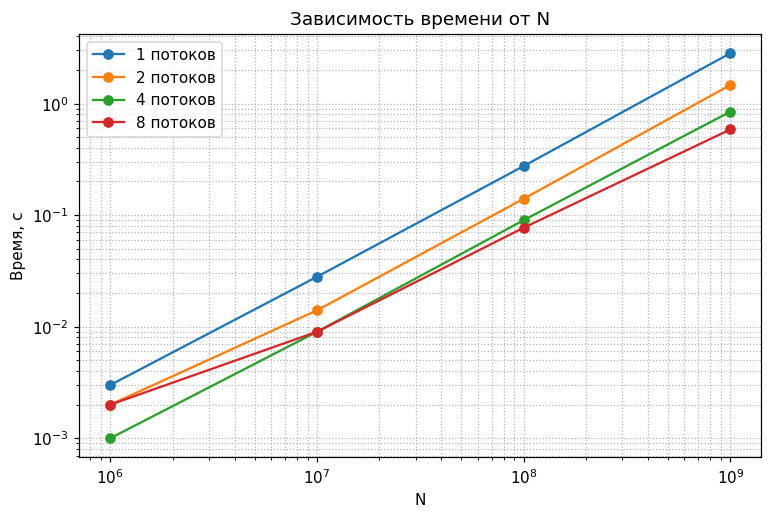

In [3]:
fig, ax = plt.subplots()
for p in threads_lst:
    sub = df[df["threads"] == p].sort_values("N")
    ax.plot(sub["N"], sub["time"], marker="o", label=f"{p} потоков")

ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("N"); ax.set_ylabel("Время, с")
ax.set_title("Зависимость времени от N")
ax.grid(True, which="both", ls=":")
ax.legend()
plt.show()

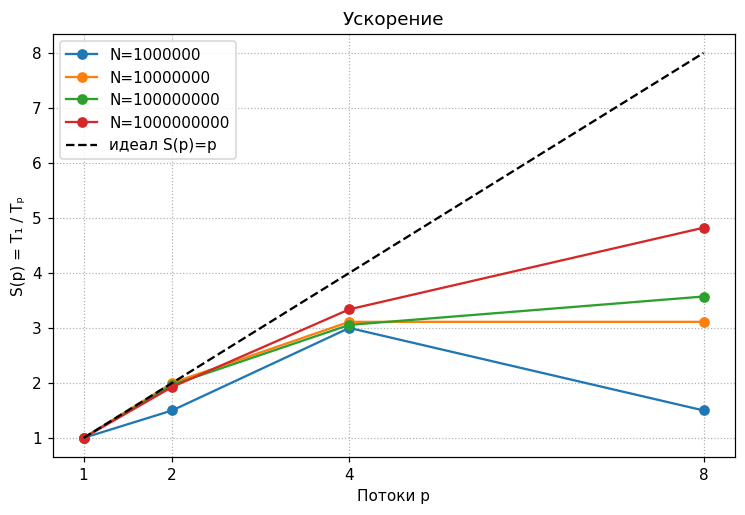

In [4]:
fig, ax = plt.subplots()
for n in Ns:
    sub = df[df["N"] == n].sort_values("threads")
    ax.plot(sub["threads"], sub["speedup"], marker="o", label=f"N={n}")

ax.plot(threads_lst, threads_lst, "k--", label="идеал S(p)=p")
ax.set_xlabel("Потоки p"); ax.set_ylabel("S(p) = T₁ / Tₚ")
ax.set_title("Ускорение")
ax.set_xticks(threads_lst)
ax.grid(True, ls=":")
ax.legend()
plt.show()

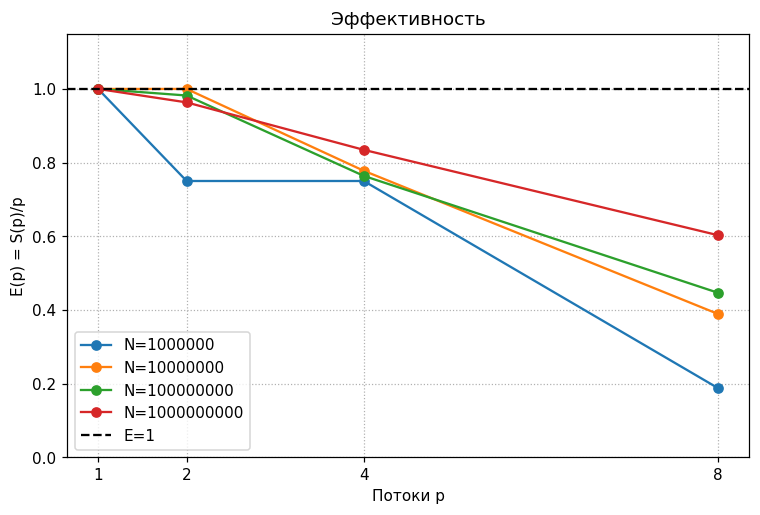

In [5]:
fig, ax = plt.subplots()
for n in Ns:
    sub = df[df["N"] == n].sort_values("threads")
    ax.plot(sub["threads"], sub["efficiency"], marker="o", label=f"N={n}")

ax.axhline(1.0, color="k", ls="--", label="E=1")
ax.set_ylim(0, 1.15)
ax.set_xlabel("Потоки p"); ax.set_ylabel("E(p) = S(p)/p")
ax.set_title("Эффективность")
ax.set_xticks(threads_lst)
ax.grid(True, ls=":")
ax.legend()
plt.show()

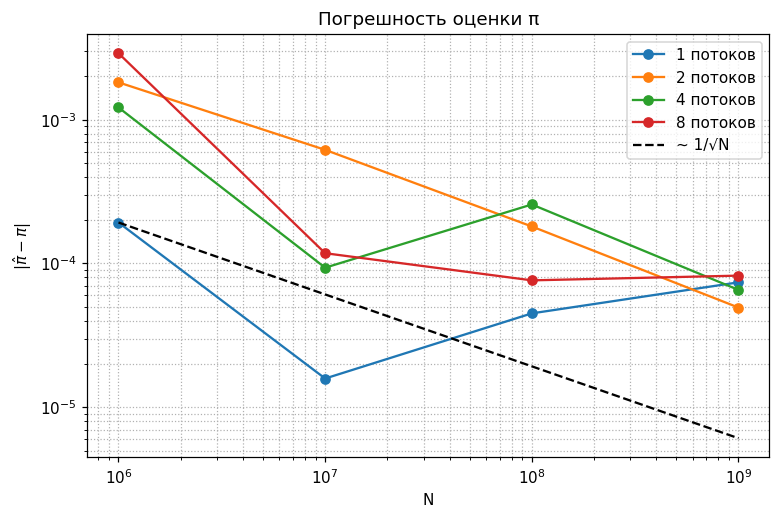

In [6]:
fig, ax = plt.subplots()
for p in threads_lst:
    sub = df[df["threads"] == p].sort_values("N")
    ax.plot(sub["N"], sub["error"], marker="o", label=f"{p} потоков")

# Теоретическая линия C/sqrt(N), привязанная к первой точке p=1
ref = df[df["threads"] == 1].sort_values("N").iloc[0]
C   = ref["error"] * np.sqrt(ref["N"])
N_arr = np.array(Ns, dtype=float)
ax.plot(N_arr, C / np.sqrt(N_arr), "k--", label="~ 1/√N")

ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("N"); ax.set_ylabel(r"$|\hat\pi - \pi|$")
ax.set_title("Погрешность оценки π")
ax.grid(True, which="both", ls=":")
ax.legend()
plt.show()